
# Digital Image Processing Lab
## Lab Task 05 – Spatial Filtering and Convolution

**University:** The University of Azad Jammu and Kashmir

**Department:** Software Engineering

**Lab Instructor:** Engr. Fahad Nisar

**Semester:** Fifth

**Session:** 2024-28 (SE)

**Student Name:** Sakeena Bano

**Roll Number:** 2024_SE_29

**Objective:** Implement 2D convolution from first principles and apply mean, Gaussian, and median filters to remove noise from images.


# Import Libraries

In [1]:

import numpy as np
import cv2
import matplotlib.pyplot as plt

from skimage import data

print("All libraries imported successfully!")


All libraries imported successfully!


# step 1:Load Three test images

In [2]:
# Load original images
camera = data.camera()
coins = data.coins()

chelsea_color = data.chelsea()
chelsea = cv2.cvtColor(chelsea_color, cv2.COLOR_RGB2GRAY)

# Display image information
print("Camera:", camera.shape)
print("Coins:", coins.shape)
print("Chelsea:", chelsea.shape)

Camera: (512, 512)
Coins: (303, 384)
Chelsea: (300, 451)


# step 2 :Display original images

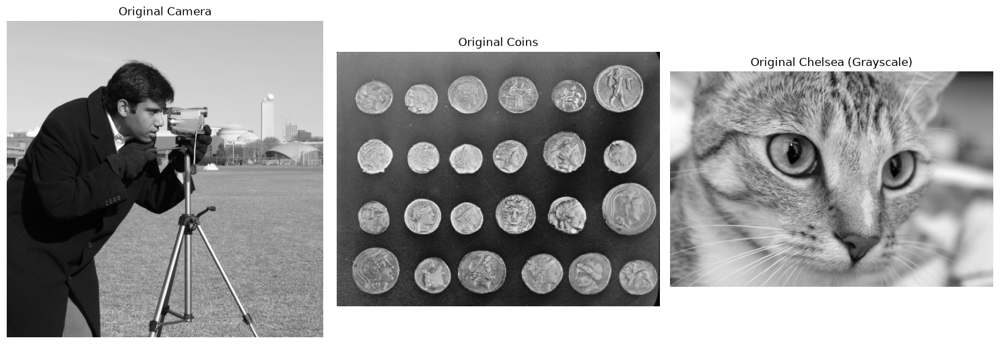

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(camera, cmap="gray")
axes[0].set_title("Original Camera")

axes[1].imshow(coins, cmap="gray")
axes[1].set_title("Original Coins")

axes[2].imshow(chelsea, cmap="gray")
axes[2].set_title("Original Chelsea (Grayscale)")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

## Step 3: Implement 2D Convolution

In [4]:
def conv2d_loop(img, kernel):
    img = img.astype(np.float64)
    kernel = np.flip(kernel, axis=(0, 1))

    kh, kw = kernel.shape
    pad_h = kh // 2
    pad_w = kw // 2

    padded = np.pad(
        img,
        ((pad_h, pad_h), (pad_w, pad_w)),
        mode="symmetric"
    )

    output = np.zeros(img.shape, dtype=np.float64)

    for i in range(img.shape[0]):
        for j in range(img.shape[1]):
            region = padded[i:i + kh, j:j + kw]
            output[i, j] = np.sum(region * kernel)

    return output

## Step 4: Verify Convolution with OpenCV

In [5]:
# Create a 3x3 mean kernel
mean_kernel = np.ones((3, 3), dtype=np.float64) / 9

# Apply custom convolution
custom_result = conv2d_loop(camera, mean_kernel)

# Apply OpenCV filtering with matching border
opencv_result = cv2.filter2D(
    camera.astype(np.float64),
    cv2.CV_64F,
    mean_kernel,
    borderType=cv2.BORDER_REFLECT
)

# Calculate difference
max_difference = np.max(np.abs(custom_result - opencv_result))

print("Custom result shape:", custom_result.shape)
print("OpenCV result shape:", opencv_result.shape)
print("Maximum difference:", max_difference)

print("Custom center value:", custom_result[100, 100])
print("OpenCV center value:", opencv_result[100, 100])

Custom result shape: (512, 512)
OpenCV result shape: (512, 512)
Maximum difference: 5.684341886080802e-14
Custom center value: 212.22222222222217
OpenCV center value: 212.22222222222217


## Step 5: Add Gaussian Noise and Salt-and-Pepper Noise

In [6]:
def add_gaussian_noise(img, sigma=20, seed=5):
    rng = np.random.default_rng(seed)
    noise = rng.normal(0, sigma, img.shape)

    noisy_img = img.astype(np.float64) + noise
    return np.clip(np.rint(noisy_img), 0, 255).astype(np.uint8)


def add_salt_pepper(img, amount=0.05, seed=5):
    rng = np.random.default_rng(seed)
    noisy_img = img.copy()

    total_pixels = img.size
    number = int(amount * total_pixels)

    indices = rng.choice(total_pixels, 2 * number, replace=False)

    flat_img = noisy_img.reshape(-1)
    flat_img[indices[:number]] = 0
    flat_img[indices[number:]] = 255

    return noisy_img


# Generate noisy versions of all images
images = {
    "Camera": camera,
    "Coins": coins,
    "Chelsea": chelsea
}

noisy_images = {}

for name, img in images.items():
    noisy_images[name] = {
        "Gaussian Noise": add_gaussian_noise(img, sigma=20, seed=5),
        "Salt and Pepper": add_salt_pepper(img, amount=0.05, seed=5)
    }

print("Gaussian and Salt-and-Pepper noise added successfully.")

Gaussian and Salt-and-Pepper noise added successfully.


## Step 6: Display Gaussian and Salt-and-Pepper Noisy Images

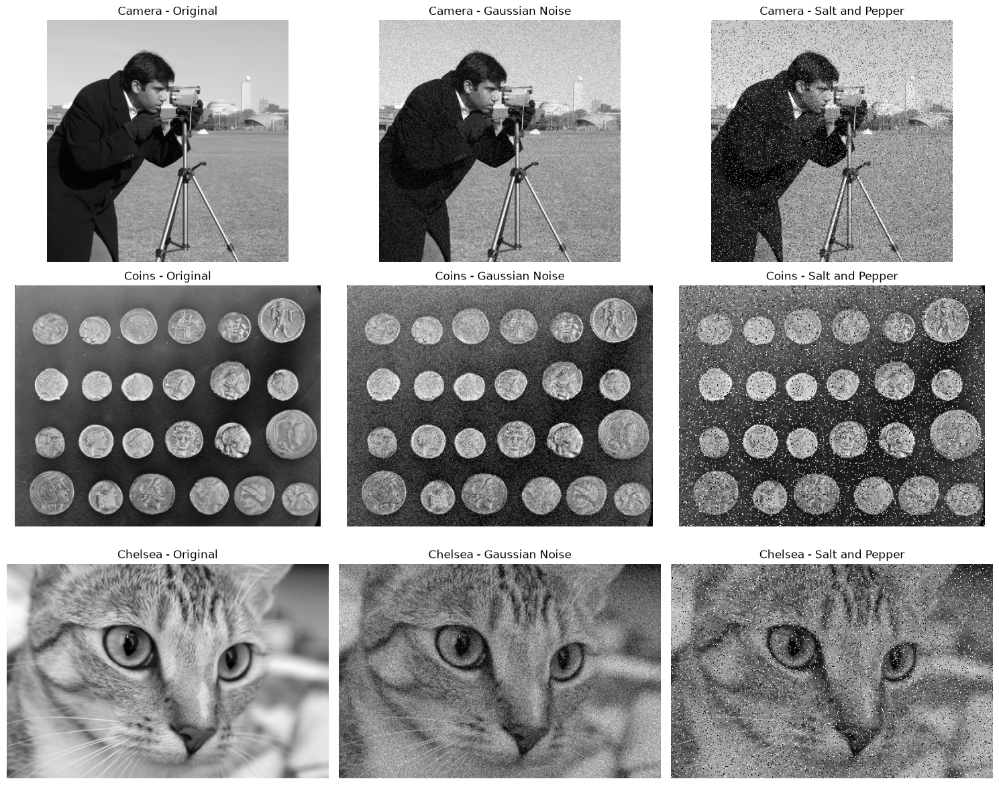

In [7]:
fig, axes = plt.subplots(3, 3, figsize=(15, 12))

for row, (name, img) in enumerate(images.items()):
    axes[row, 0].imshow(img, cmap="gray")
    axes[row, 0].set_title(f"{name} - Original")

    axes[row, 1].imshow(
        noisy_images[name]["Gaussian Noise"], cmap="gray"
    )
    axes[row, 1].set_title(f"{name} - Gaussian Noise")

    axes[row, 2].imshow(
        noisy_images[name]["Salt and Pepper"], cmap="gray"
    )
    axes[row, 2].set_title(f"{name} - Salt and Pepper")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

## Step 7: Implement Mean, Gaussian and Median Filters

In [8]:
def convert_to_uint8(img):
    return np.clip(np.rint(img), 0, 255).astype(np.uint8)


def mean_filter(img, size=3):
    kernel = np.ones((size, size), dtype=np.float64) / (size * size)
    result = conv2d_loop(img, kernel)
    return convert_to_uint8(result)


def gaussian_filter(img, size=3):
    gaussian_1d = cv2.getGaussianKernel(size, 0)
    kernel = gaussian_1d @ gaussian_1d.T

    result = cv2.filter2D(
        img.astype(np.float64),
        cv2.CV_64F,
        kernel,
        borderType=cv2.BORDER_REFLECT
    )

    return convert_to_uint8(result)


def median_filter(img, size=3):
    if size % 2 == 0:
        raise ValueError("Kernel size must be odd.")

    return cv2.medianBlur(img.astype(np.uint8), size)


print("Mean, Gaussian and Median filters created successfully.")

Mean, Gaussian and Median filters created successfully.


## Step 8: Apply Filters to Noisy Images

In [9]:
filtered_images = {}

for name in images:
    filtered_images[name] = {}

    for noise_type, noisy_img in noisy_images[name].items():
        filtered_images[name][noise_type] = {
            "Mean": mean_filter(noisy_img, 3),
            "Gaussian": gaussian_filter(noisy_img, 3),
            "Median": median_filter(noisy_img, 3)
        }

print("All filters applied successfully.")

All filters applied successfully.


## Step 9: Display Filtered Images

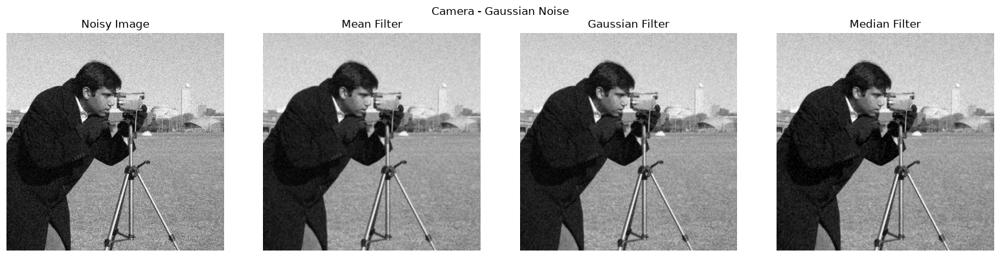

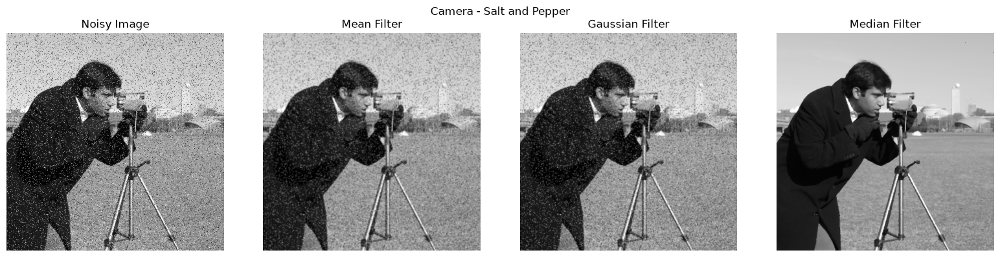

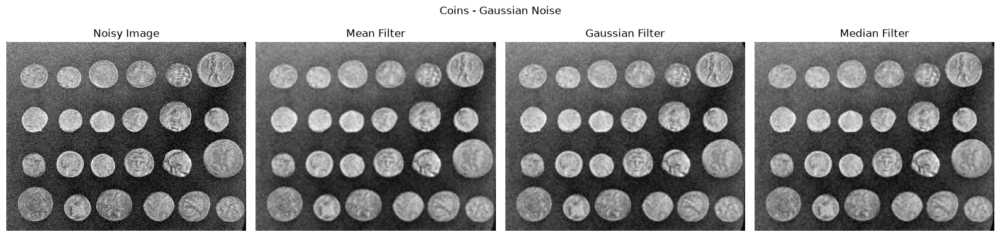

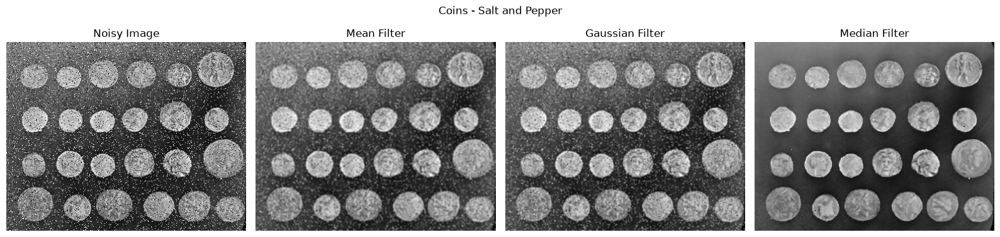

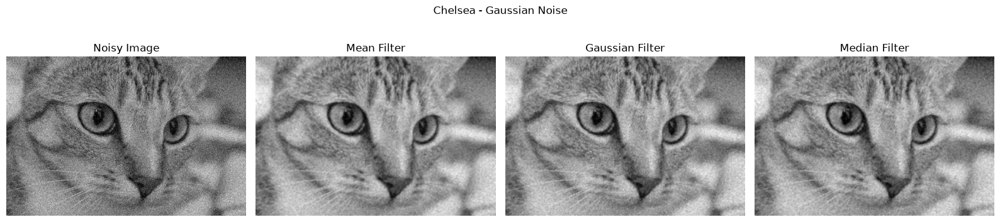

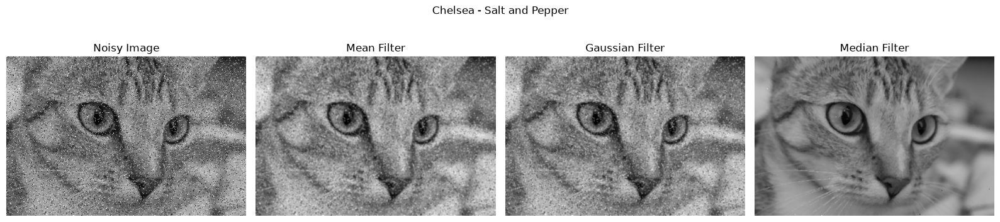

In [10]:
for name in images:
    for noise_type in ["Gaussian Noise", "Salt and Pepper"]:

        results = filtered_images[name][noise_type]

        fig, axes = plt.subplots(1, 4, figsize=(16, 4))

        axes[0].imshow(noisy_images[name][noise_type], cmap="gray")
        axes[0].set_title("Noisy Image")

        for index, (filter_name, result) in enumerate(results.items(), start=1):
            axes[index].imshow(result, cmap="gray")
            axes[index].set_title(filter_name + " Filter")

        for ax in axes:
            ax.axis("off")

        plt.suptitle(f"{name} - {noise_type}")
        plt.tight_layout()
        plt.show()

## Step 10: Apply Filters with Different Kernel Sizes

In [11]:
kernel_sizes = [3, 5, 7]

filtered_results = {}

for name in images:
    filtered_results[name] = {}

    for noise_type, noisy_img in noisy_images[name].items():
        filtered_results[name][noise_type] = {}

        for size in kernel_sizes:
            filtered_results[name][noise_type][size] = {
                "Mean": mean_filter(noisy_img, size),
                "Gaussian": gaussian_filter(noisy_img, size),
                "Median": median_filter(noisy_img, size)
            }

print("All filters applied with 3x3, 5x5 and 7x7 kernels.")

All filters applied with 3x3, 5x5 and 7x7 kernels.


## Step 11: Compare Different Kernel Sizes

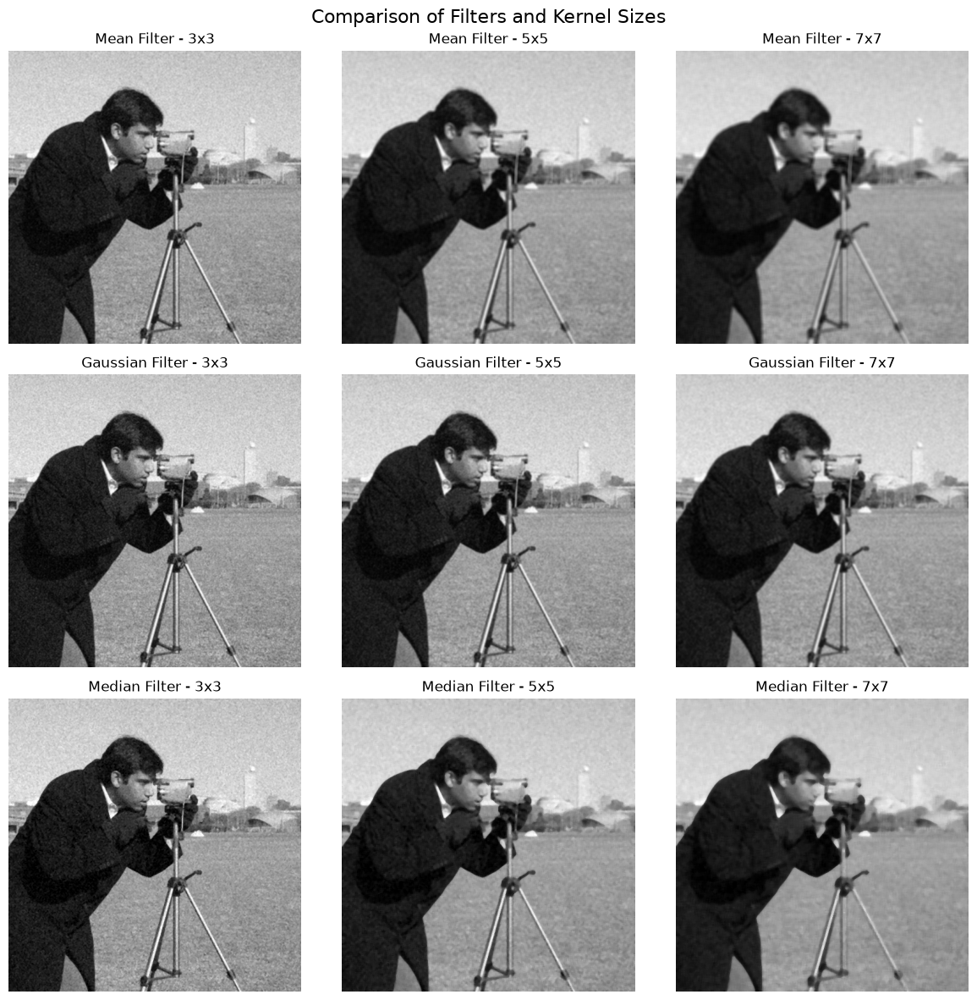

In [12]:
fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for row, filter_name in enumerate(["Mean", "Gaussian", "Median"]):
    for col, size in enumerate([3, 5, 7]):

        result = filtered_results["Camera"]["Gaussian Noise"][size][filter_name]

        axes[row, col].imshow(result, cmap="gray")
        axes[row, col].set_title(f"{filter_name} Filter - {size}x{size}")
        axes[row, col].axis("off")

plt.suptitle("Comparison of Filters and Kernel Sizes", fontsize=16)
plt.tight_layout()
plt.show()

## Step 12: Check Output Requirements

In [13]:
# Check filtered image properties
for name in filtered_results:
    for noise_type in filtered_results[name]:
        for size in filtered_results[name][noise_type]:
            for filter_name, result in filtered_results[name][noise_type][size].items():

                assert result.shape == images[name].shape
                assert result.dtype == np.uint8
                assert result.min() >= 0
                assert result.max() <= 255

print("R1: Image shapes verified.")
print("R2: Output data types and pixel ranges verified.")

# Check smoothing kernel sums
for size in [3, 5, 7]:
    mean_kernel = np.ones((size, size), dtype=np.float64) / (size * size)

    gaussian_1d = cv2.getGaussianKernel(size, 0)
    gaussian_kernel = gaussian_1d @ gaussian_1d.T

    print(f"{size}x{size} Mean kernel sum:", mean_kernel.sum())
    print(f"{size}x{size} Gaussian kernel sum:", gaussian_kernel.sum())

print("R3: Smoothing kernel sums verified.")
print("R4: Odd kernel sizes 3, 5 and 7 used.")
print("R5: Noise seed set to 5.")

R1: Image shapes verified.
R2: Output data types and pixel ranges verified.
3x3 Mean kernel sum: 1.0
3x3 Gaussian kernel sum: 1.0
5x5 Mean kernel sum: 1.0
5x5 Gaussian kernel sum: 1.0
7x7 Mean kernel sum: 0.9999999999999999
7x7 Gaussian kernel sum: 1.0
R3: Smoothing kernel sums verified.
R4: Odd kernel sizes 3, 5 and 7 used.
R5: Noise seed set to 5.


## Step 13: Verify Mean Filter with OpenCV

In [14]:
# Apply custom mean filter
custom_mean = mean_filter(camera, 3)

# Apply OpenCV mean filter
opencv_mean = cv2.blur(
    camera,
    (3, 3),
    borderType=cv2.BORDER_REFLECT
)

# Calculate maximum difference
difference = np.max(
    np.abs(custom_mean.astype(np.int16) - opencv_mean.astype(np.int16))
)

print("Custom Mean Filter dtype:", custom_mean.dtype)
print("OpenCV Mean Filter dtype:", opencv_mean.dtype)
print("Maximum Difference:", difference)

if difference <= 1:
    print("Mean Filter Verification: PASSED")
else:
    print("Mean Filter Verification: CHECK REQUIRED")

Custom Mean Filter dtype: uint8
OpenCV Mean Filter dtype: uint8
Maximum Difference: 0
Mean Filter Verification: PASSED


## Step 14: Verify Median Filter and Even Kernel Rejection

In [15]:
# Apply median filter with valid odd kernel size
median_result = cv2.medianBlur(camera, 3)

print("Median Filter Output Shape:", median_result.shape)
print("Median Filter Output Type:", median_result.dtype)

# Demonstrate rejection of even kernel size
try:
    cv2.medianBlur(camera, 4)
except cv2.error:
    print("Even kernel size 4 rejected successfully.")

# Check valid kernel size
print("Valid odd kernel size 3 accepted successfully.")

Median Filter Output Shape: (512, 512)
Median Filter Output Type: uint8
Even kernel size 4 rejected successfully.
Valid odd kernel size 3 accepted successfully.


## Step 15: Verify Noise Reproducibility

In [16]:
# Generate Gaussian noise again
gaussian_again = add_gaussian_noise(camera, sigma=20, seed=5)

# Generate Salt-and-Pepper noise again
salt_pepper_again = add_salt_pepper(camera, amount=0.05, seed=5)

# Compare results
gaussian_same = np.array_equal(
    noisy_images["Camera"]["Gaussian Noise"],
    gaussian_again
)

salt_pepper_same = np.array_equal(
    noisy_images["Camera"]["Salt and Pepper"],
    salt_pepper_again
)

print("Gaussian Noise Reproducibility:", gaussian_same)
print("Salt-and-Pepper Reproducibility:", salt_pepper_same)

Gaussian Noise Reproducibility: True
Salt-and-Pepper Reproducibility: True


## Step 16: Compare Filtered Images Using MSE

In [17]:
def calculate_mse(original, filtered):
    original = original.astype(np.float64)
    filtered = filtered.astype(np.float64)
    return np.mean((original - filtered) ** 2)


for name in images:
    print("\n", name)

    for noise_type in noisy_images[name]:
        print("\n", noise_type)

        for filter_name, result in filtered_images[name][noise_type].items():
            mse = calculate_mse(images[name], result)

            print(f"{filter_name} Filter MSE: {mse:.2f}")


 Camera

 Gaussian Noise
Mean Filter MSE: 118.95
Gaussian Filter MSE: 103.35
Median Filter MSE: 131.39

 Salt and Pepper
Mean Filter MSE: 368.95
Gaussian Filter MSE: 405.66
Median Filter MSE: 71.42

 Coins

 Gaussian Noise
Mean Filter MSE: 168.21
Gaussian Filter MSE: 135.96
Median Filter MSE: 163.20

 Salt and Pepper
Mean Filter MSE: 401.26
Gaussian Filter MSE: 417.84
Median Filter MSE: 111.51

 Chelsea

 Gaussian Noise
Mean Filter MSE: 72.03
Gaussian Filter MSE: 73.85
Median Filter MSE: 96.66

 Salt and Pepper
Mean Filter MSE: 236.81
Gaussian Filter MSE: 277.43
Median Filter MSE: 31.24


## Step 17: Dry Run Exercise 1 – Manual Filter Calculation

Consider the following 3×3 neighbourhood:

```text
40   40   40
40  255   40
40   40   40
```

**Mean Filter:**

Sum = 40 + 40 + 40 + 40 + 255 + 40 + 40 + 40 + 40 = 575

Mean = 575 / 9 = 63.89

**Gaussian Filter:**

Using the Gaussian kernel:

```text
1/16   2/16   1/16
2/16   4/16   2/16
1/16   2/16   1/16
```

Weighted sum = 1500

Gaussian result = 1500 / 16 = 93.75

**Median Filter:**

Median = 40

**Conclusion:** The Mean and Gaussian filters reduce the central bright pixel's intensity, while the Median filter removes its effect more strongly.

In [18]:
neighborhood = np.array([
    [40, 40, 40],
    [40, 255, 40],
    [40, 40, 40]
], dtype=np.float64)

mean_value = np.sum(neighborhood) / 9

gaussian_kernel = np.array([
    [1, 2, 1],
    [2, 4, 2],
    [1, 2, 1]
], dtype=np.float64) / 16

gaussian_value = np.sum(neighborhood * gaussian_kernel)
median_value = np.median(neighborhood)

print("Mean Filter:", mean_value)
print("Gaussian Filter:", gaussian_value)
print("Median Filter:", median_value)

Mean Filter: 63.888888888888886
Gaussian Filter: 93.75
Median Filter: 40.0


## Step 18: Dry Run Exercise 2

Given image:

[[10, 20, 30],
 [40, 50, 60],
 [70, 80, 90]]

Calculate the top-left pixel using a 3x3 mean filter with reflect padding.

Expected neighbourhood:
[[50, 40, 50],
 [20, 10, 20],
 [50, 40, 50]]

Expected sum = 330
Expected mean = 36.67

In [19]:
small_img = np.array([
    [10, 20, 30],
    [40, 50, 60],
    [70, 80, 90]
], dtype=np.float64)

padded_img = np.pad(small_img, ((1, 1), (1, 1)), mode="symmetric")

neighborhood = padded_img[0:3, 0:3]

total = np.sum(neighborhood)
mean_value = total / 9

print("Top-left Neighborhood:")
print(neighborhood)
print("Sum:", total)
print("Mean:", mean_value)

Top-left Neighborhood:
[[10. 10. 20.]
 [10. 10. 20.]
 [40. 40. 50.]]
Sum: 210.0
Mean: 23.333333333333332


## Step 19: Comparison of 3x3, 5x5 and 7x7 Filters

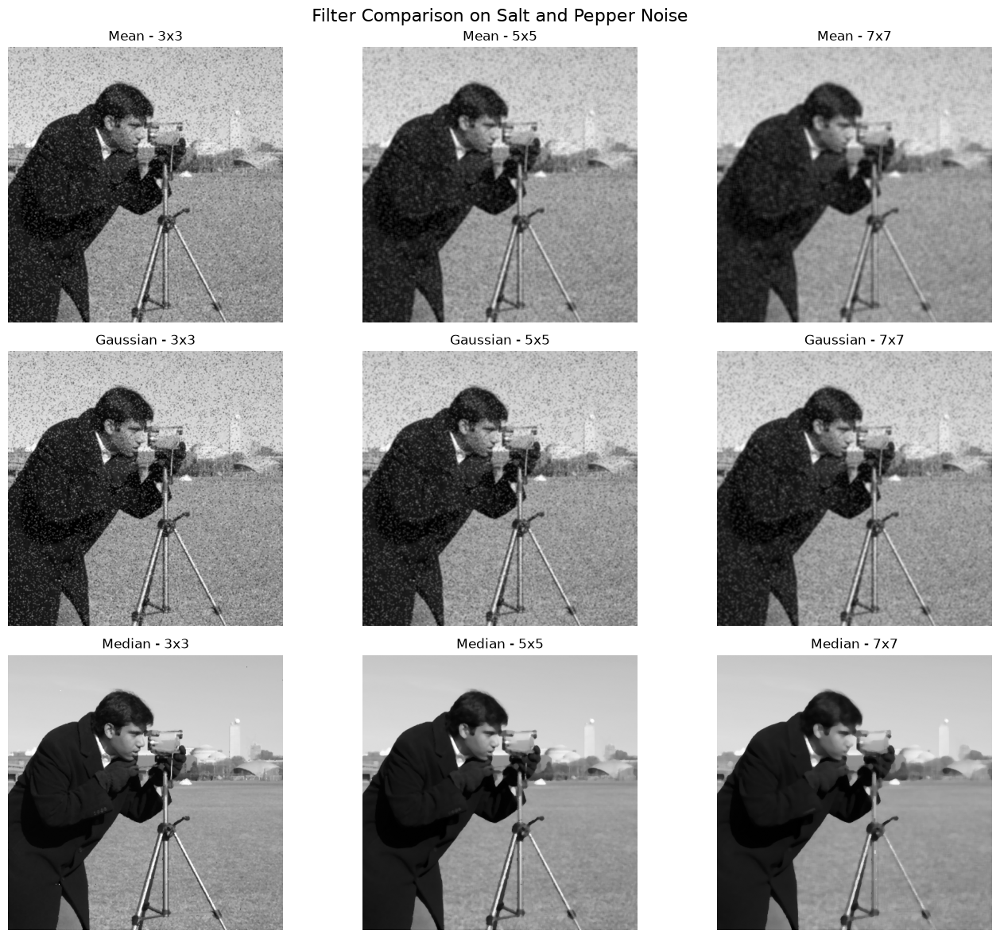

In [20]:
fig, axes = plt.subplots(3, 3, figsize=(14, 12))

for row, filter_name in enumerate(["Mean", "Gaussian", "Median"]):
    for col, size in enumerate([3, 5, 7]):

        result = filtered_results["Camera"]["Salt and Pepper"][size][filter_name]

        axes[row, col].imshow(result, cmap="gray")
        axes[row, col].set_title(f"{filter_name} - {size}x{size}")
        axes[row, col].axis("off")

plt.suptitle("Filter Comparison on Salt and Pepper Noise", fontsize=16)
plt.tight_layout()
plt.show()

## Step 20: MSE Comparison for Different Kernel Sizes

In [21]:
for filter_name in ["Mean", "Gaussian", "Median"]:
    print("\n", filter_name, "Filter")

    for size in [3, 5, 7]:
        result = filtered_results["Camera"]["Salt and Pepper"][size][filter_name]
        mse = calculate_mse(camera, result)

        print(f"{size}x{size} MSE:", round(mse, 2))


 Mean Filter
3x3 MSE: 368.95
5x5 MSE: 285.7
7x7 MSE: 308.61

 Gaussian Filter
3x3 MSE: 405.66
5x5 MSE: 296.58
7x7 MSE: 261.45

 Median Filter
3x3 MSE: 71.42
5x5 MSE: 110.13
7x7 MSE: 156.21


## Step 21: Observations

### 1. Gaussian Noise
Gaussian filtering generally performs well on Gaussian noise. It smooths random intensity variations while preserving more details than a large mean filter.

### 2. Salt-and-Pepper Noise
Median filtering performs best for salt-and-pepper noise because it replaces extreme black and white pixels with the median value of their neighbourhood.

### 3. Mean vs Gaussian Filter
Mean filtering gives equal importance to all pixels, while Gaussian filtering gives more importance to nearby pixels. Gaussian filtering generally preserves edges better.

### 4. Effect of 7×7 Kernel
A 7×7 kernel removes more noise but can blur fine details and edges.

### 5. Odd Kernel Size
Odd kernel sizes provide a clear center pixel, which makes neighbourhood filtering easier.

### 6. Image Comparison
The MSE values show that Gaussian filtering performs best for most Gaussian-noisy images, while median filtering performs best for salt-and-pepper noisy images.

### 7. Observations from MSE Comparison

For the Camera image with Salt-and-Pepper noise, the 3×3 Median Filter achieved the lowest MSE of 71.42.

The Mean Filter performed best at 5×5 with an MSE of 285.70, while the Gaussian Filter performed best at 7×7 with an MSE of 261.45.

The results show that increasing kernel size does not always improve image quality. The 3×3 Median Filter preserved image details and removed Salt-and-Pepper noise more effectively.

### 8. Visual Observations

In the filtered image comparison, the Median Filter removes most black and white noise spots while maintaining important image structures. Larger kernels produce stronger smoothing but may remove fine details and edges.

## Step 22: Viva Questions and Answers

**Q1. What is a kernel?**

A kernel is a small matrix used to perform image processing operations such as smoothing and sharpening.

**Q2. Why does median filtering remove salt-and-pepper noise?**

Median filtering replaces the center pixel with the median of its neighbourhood, removing extreme values such as 0 and 255.

**Q3. Why do Gaussian kernel weights sum to 1?**

The weights sum to 1 to preserve the overall image brightness.

**Q4. Why is padding required?**

Padding allows filtering at image boundaries while maintaining the original image size.

**Q5. Which filter is best for salt-and-pepper noise?**

Median filtering is generally the best choice for salt-and-pepper noise.

## Step 23: Final Verification

In [22]:
print("Final Lab Task 05 Verification")

print("1. Convolution function:", callable(conv2d_loop))
print("2. Gaussian noise:", "Camera" in noisy_images)
print("3. Salt-and-Pepper noise:", "Camera" in noisy_images)
print("4. Mean filter:", callable(mean_filter))
print("5. Gaussian filter:", callable(gaussian_filter))
print("6. Median filter:", callable(median_filter))
print("7. Kernel sizes:", kernel_sizes)
print("8. Dry Run Exercise 1:", mean_value if 'mean_value' in globals() else "Completed")
print("9. Filtered images:", len(filtered_results))

print("\nLab Task 05 completed.")

Final Lab Task 05 Verification
1. Convolution function: True
2. Gaussian noise: True
3. Salt-and-Pepper noise: True
4. Mean filter: True
5. Gaussian filter: True
6. Median filter: True
7. Kernel sizes: [3, 5, 7]
8. Dry Run Exercise 1: 23.333333333333332
9. Filtered images: 3

Lab Task 05 completed.
